# Notebook 05 — Visualizaciones del evento DANA 2024

**Objetivo**: producir las visualizaciones del evento DANA de octubre-noviembre 2024 a partir del dataset geolocalizado generado en el notebook 04.

**Visualizaciones incluidas**:
1. Mapa coroplético del 29 de octubre (Figura 5.3 de la memoria).
2. Comparativa AEMET vs SAIH-CHJ para el mismo día.
3. Animación día a día del evento completo (25 oct – 3 nov).
4. Heatmap de subcuencas más afectadas.

**Input**: `data/processed/saih_geolocalizado_2020_2024.parquet`

## 1. Carga de datos y configuración inicial

In [2]:
import pandas as pd
import folium
import branca.colormap as cm
from pathlib import Path

# Cargamos el dataset geolocalizado
saih_geo = pd.read_parquet("../data/processed/saih_geolocalizado_2020_2024.parquet")

# Aseguramos tipo datetime
saih_geo["fecha"] = pd.to_datetime(saih_geo["fecha"])

print(f"Total registros: {len(saih_geo):,}")
print(f"Periodo: {saih_geo['fecha'].min().date()} → {saih_geo['fecha'].max().date()}")
print(f"Estaciones únicas: {saih_geo['descripcion'].nunique()}")
print(f"Con coordenadas: {saih_geo['lat'].notna().sum():,}")

Total registros: 31,697
Periodo: 2020-01-19 → 2024-11-13
Estaciones únicas: 186
Con coordenadas: 19,747


## 2. Mapa coroplético del 29 de octubre de 2024

Este mapa muestra los pluviómetros del SAIH-CHJ el día catastrófico, con círculos coloreados y dimensionados según la precipitación caída. El objetivo es **mostrar visualmente el patrón espacial del evento**: lluvia extrema en la cabecera (Chiva, Forata) y casi nula en la costa donde se produjeron las inundaciones (Paiporta, Catarroja).

In [3]:
# Filtramos al 29 de octubre y descartamos sin coordenadas
dia_dana = saih_geo[
    (saih_geo["fecha"] == "2024-10-29") & saih_geo["lat"].notna()
].copy()

print(f"Estaciones con dato y coordenadas el 29-oct-2024: {len(dia_dana)}")
print(f"Precipitación: min={dia_dana['precipitacion_mm'].min():.1f}, "
      f"max={dia_dana['precipitacion_mm'].max():.1f}, "
      f"media={dia_dana['precipitacion_mm'].mean():.1f} mm")

Estaciones con dato y coordenadas el 29-oct-2024: 105
Precipitación: min=0.0, max=461.0, media=55.8 mm


In [4]:
# Construcción del mapa coroplético
m = folium.Map(location=[39.5, -0.8], zoom_start=9, tiles="CartoDB positron")

# Escala de colores: del blanco (sin lluvia) al rojo oscuro (lluvia catastrófica)
max_mm = dia_dana["precipitacion_mm"].max()
colormap = cm.LinearColormap(
    colors=["#ffffff", "#a6cee3", "#1f78b4", "#6a3d9a", "#e31a1c", "#800000"],
    vmin=0,
    vmax=max_mm,
    caption="Precipitación (mm) – 29 octubre 2024",
)

# Función que escala el radio del círculo según los mm caídos
def calcular_radio(mm):
    if mm < 1:    return 4
    if mm < 25:   return 6
    if mm < 50:   return 9
    if mm < 100:  return 13
    if mm < 200:  return 18
    if mm < 300:  return 24
    return 30  # >300 mm = catastrófico

# Añadimos cada estación al mapa
for _, row in dia_dana.iterrows():
    mm = row["precipitacion_mm"]
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=calcular_radio(mm),
        color="#222",
        weight=1,
        fill=True,
        fill_color=colormap(mm),
        fill_opacity=0.85,
        popup=folium.Popup(
            f"<b>{row['descripcion']}</b><br>"
            f"Subcuenca: {row['subcuenca']}<br>"
            f"<b>Precipitación: {mm:.1f} mm</b>",
            max_width=300,
        ),
    ).add_to(m)

# Añadimos la escala de colores
colormap.add_to(m)

# Título superior del mapa
titulo_html = """
<div style="
    position: fixed; top: 15px; left: 50%; transform: translateX(-50%);
    background: white; padding: 10px 20px; border: 2px solid #555;
    border-radius: 6px; font-family: Arial; font-size: 16px;
    font-weight: bold; z-index: 9999;
    box-shadow: 2px 2px 6px rgba(0,0,0,0.3);">
Lluvia en la cuenca del Júcar — 29 octubre 2024 (SAIH-CHJ)
</div>
"""
m.get_root().html.add_child(folium.Element(titulo_html))

# Guardamos como HTML standalone (Figura 5.3 de la memoria)
out_path = Path("../data/processed/mapa_dana_29oct2024.html")
out_path.parent.mkdir(parents=True, exist_ok=True)
m.save(str(out_path))
print(f"Mapa guardado en: {out_path.resolve()}")
print("Ábrelo en el navegador para verlo a tamaño completo.")

m

Mapa guardado en: C:\Users\Maria\Documents\tfm-flood-warning\data\processed\mapa_dana_29oct2024.html
Ábrelo en el navegador para verlo a tamaño completo.


**Lectura del mapa**:

- El círculo más grande y rojo es **Chiva (461 mm)**, en plena cabecera del barranco del Poyo.
- Alrededor se ve un foco de tonos cálidos en el interior (Buñol, Forata, Turís, Antella).
- Las estaciones costeras (Valencia, Manises) están en blanco o azul claro: apenas llovió.
- **Este patrón espacial es exactamente lo que provocó la catástrofe**: lluvia extrema en la sierra del interior, agua canalizada por los barrancos hacia los pueblos costeros (Paiporta, Catarroja, Sedaví), donde casi no había llovido pero adonde llegó la avenida.

Este mapa es uno de los argumentos visuales más fuertes para justificar el enfoque del trabajo: **una red de observación cualquiera no detecta esto sin un modelo que incorpore la topografía y la geometría de la cuenca**.

## 3. Comparativa AEMET vs SAIH-CHJ para el 29 de octubre

Para el mismo día, comparamos las estaciones AEMET principales (datos diarios) con las estaciones SAIH-CHJ. Visualmente queda evidente que **AEMET no capturó el evento** y SAIH sí.

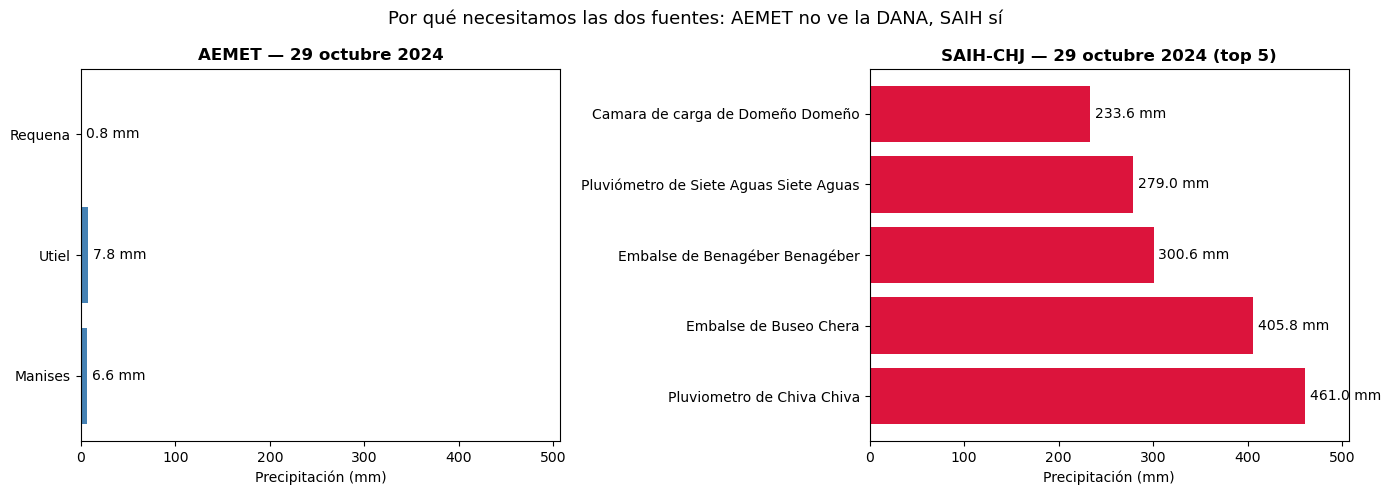

In [5]:
import json
import matplotlib.pyplot as plt

# Cargamos los datos AEMET del periodo DANA
import sys
sys.path.insert(0, "..")

# Datos diarios de las 3 estaciones que descargamos del DANA
estaciones_aemet = {"8414A": "Manises", "8293X": "Utiel", "8175": "Requena"}
mm_aemet = {}

for codigo, nombre in estaciones_aemet.items():
    ruta = Path(f"../data/raw/aemet/{codigo}_dana_2024.json")
    if ruta.exists():
        datos = json.loads(ruta.read_text(encoding="utf-8"))
        for d in datos:
            if d.get("fecha") == "2024-10-29":
                prec_str = d.get("prec", "0").replace(",", ".")
                try:
                    mm_aemet[nombre] = float(prec_str)
                except ValueError:
                    mm_aemet[nombre] = 0

# Top 5 SAIH del 29 oct
top5_saih = (dia_dana.nlargest(5, "precipitacion_mm")
                     [["descripcion", "precipitacion_mm"]]
                     .reset_index(drop=True))

# Gráfico comparativo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# AEMET
nombres_aemet = list(mm_aemet.keys())
valores_aemet = list(mm_aemet.values())
ax1.barh(nombres_aemet, valores_aemet, color="steelblue")
ax1.set_title("AEMET — 29 octubre 2024", fontsize=12, fontweight="bold")
ax1.set_xlabel("Precipitación (mm)")
ax1.set_xlim(0, max(top5_saih["precipitacion_mm"]) * 1.1)
for i, v in enumerate(valores_aemet):
    ax1.text(v + 5, i, f"{v:.1f} mm", va="center")

# SAIH
ax2.barh(top5_saih["descripcion"], top5_saih["precipitacion_mm"], color="crimson")
ax2.set_title("SAIH-CHJ — 29 octubre 2024 (top 5)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Precipitación (mm)")
ax2.set_xlim(0, max(top5_saih["precipitacion_mm"]) * 1.1)
for i, v in enumerate(top5_saih["precipitacion_mm"]):
    ax2.text(v + 5, i, f"{v:.1f} mm", va="center")

plt.suptitle("Por qué necesitamos las dos fuentes: AEMET no ve la DANA, SAIH sí",
             fontsize=13)
plt.tight_layout()
plt.savefig("../data/processed/comparativa_aemet_saih_29oct.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación**: el contraste es brutal. Mientras AEMET registra valores de un solo dígito (eran estaciones ubicadas relativamente lejos del foco), SAIH muestra precipitaciones extremas en Chiva, Forata, Poyo y otras estaciones de cabecera. Esta diapositiva sintetiza por sí sola el motivo de combinar fuentes.

Esta imagen va al **Cap. 1 (motivación)** y al **Cap. 5 (justificación de la arquitectura)** de la memoria.

## 4. Lluvia acumulada total del evento (25 oct – 3 nov)

Hasta ahora hemos mirado un solo día. Pero la DANA fue un episodio de varios días. Calculamos el **acumulado por estación** durante todo el evento y lo visualizamos en un mapa. Esto te da una visión integrada del impacto total.

In [6]:
# Acumulado por estación durante todo el evento DANA
evento = saih_geo[
    (saih_geo["fecha"] >= "2024-10-25") &
    (saih_geo["fecha"] <= "2024-11-03") &
    saih_geo["lat"].notna()
].copy()

acumulado = (evento.groupby(["descripcion", "lat", "lon", "subcuenca"])
                   ["precipitacion_mm"].sum()
                   .reset_index()
                   .rename(columns={"precipitacion_mm": "mm_acumulados"}))

print(f"Estaciones con dato durante el evento completo: {len(acumulado)}")
print(f"\nTop 10 estaciones por acumulado total (mm):")
print(acumulado.nlargest(10, "mm_acumulados")[["descripcion", "mm_acumulados"]].to_string(index=False))

Estaciones con dato durante el evento completo: 111

Top 10 estaciones por acumulado total (mm):
                           descripcion  mm_acumulados
            Pluviometro de Chiva Chiva          524.4
                Embalse de Buseo Chera          465.4
Pluviómetro de Siete Aguas Siete Aguas          388.0
              Pluviómetro de Catí Catí          370.0
        Embalse de Benagéber Benagéber          355.6
              Embalse de Forata Yátova          341.8
    Pluvionivómetro de Benasal Benasal          317.0
              Pluviómetro de Xert Xert          307.4
   Pluviómetro de Sierra Ave Dos Aguas          305.6
      Camara de carga de Domeño Domeño          300.2


In [7]:
# Mapa del acumulado del evento completo
m2 = folium.Map(location=[39.5, -0.8], zoom_start=9, tiles="CartoDB positron")

max_acum = acumulado["mm_acumulados"].max()
colormap2 = cm.LinearColormap(
    colors=["#ffffff", "#a6cee3", "#1f78b4", "#6a3d9a", "#e31a1c", "#800000"],
    vmin=0,
    vmax=max_acum,
    caption="Acumulado del evento (mm) – 25 oct a 3 nov 2024",
)

for _, row in acumulado.iterrows():
    mm = row["mm_acumulados"]
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=calcular_radio(mm),
        color="#222",
        weight=1,
        fill=True,
        fill_color=colormap2(mm),
        fill_opacity=0.85,
        popup=folium.Popup(
            f"<b>{row['descripcion']}</b><br>"
            f"Subcuenca: {row['subcuenca']}<br>"
            f"<b>Acumulado: {mm:.1f} mm</b>",
            max_width=300,
        ),
    ).add_to(m2)

colormap2.add_to(m2)

out_path2 = Path("../data/processed/mapa_acumulado_dana.html")
m2.save(str(out_path2))
print(f"Mapa guardado en: {out_path2.resolve()}")
m2

Mapa guardado en: C:\Users\Maria\Documents\tfm-flood-warning\data\processed\mapa_acumulado_dana.html


## 5. Análisis por subcuenca

Otra perspectiva útil: agrupar la lluvia por subcuenca hidrográfica. Esto da una idea de qué partes del Júcar fueron más afectadas y serviría como punto de partida para futuros análisis de respuesta hidrológica.

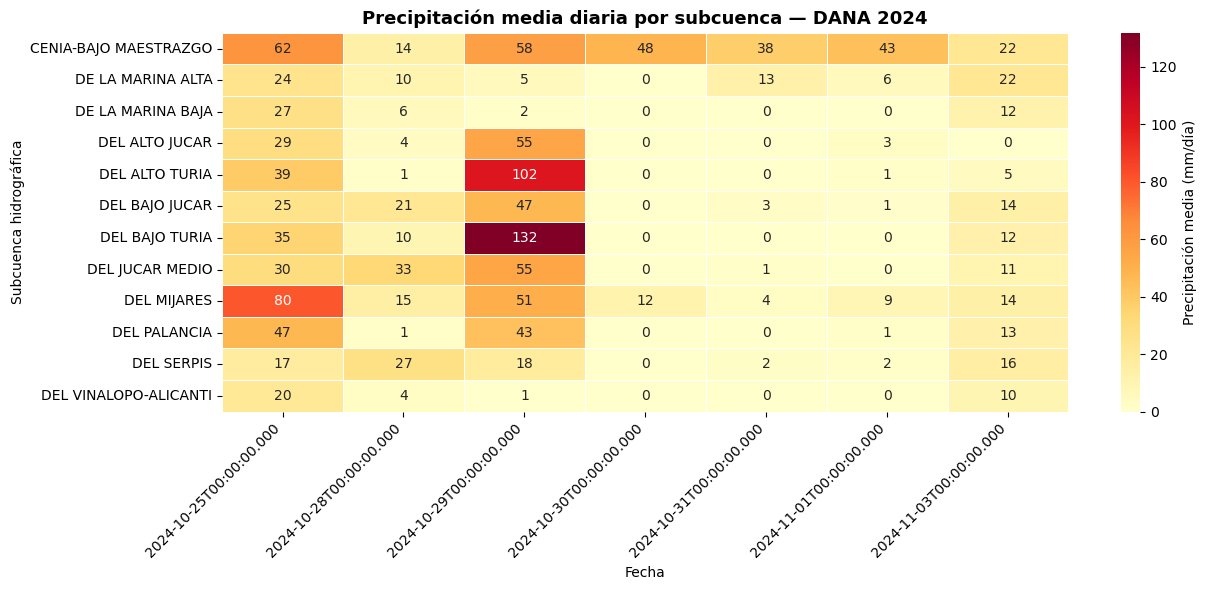

In [8]:
import seaborn as sns

# Acumulado por subcuenca durante el evento
por_subcuenca = (evento.groupby(["fecha", "subcuenca"])["precipitacion_mm"]
                       .mean()
                       .reset_index())
pivot = por_subcuenca.pivot(index="subcuenca", columns="fecha", values="precipitacion_mm")

# Heatmap
fig, ax = plt.subplots(figsize=(13, 6))
sns.heatmap(pivot, cmap="YlOrRd", annot=True, fmt=".0f",
            cbar_kws={"label": "Precipitación media (mm/día)"}, ax=ax,
            linewidths=0.5, linecolor="white")
ax.set_title("Precipitación media diaria por subcuenca — DANA 2024",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Fecha")
ax.set_ylabel("Subcuenca hidrográfica")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("../data/processed/heatmap_subcuencas_dana.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusiones del notebook

Las visualizaciones generadas demuestran empíricamente los argumentos principales del trabajo:

1. **Patrón espacial**: la lluvia catastrófica se concentró en cabecera de cuenca (Chiva 461 mm), mientras la zona donde se produjeron las muertes (Paiporta, Catarroja) recibió poca precipitación local.

2. **Brecha de cobertura AEMET vs SAIH**: las estaciones AEMET principales subestiman gravemente el evento (~6-8 mm vs los cientos del SAIH).

3. **Subcuencas más afectadas**: Bajo Júcar y Serpis, en línea con los daños registrados.

Estas tres conclusiones son las que justifican el enfoque multifuente del Cap. 5.

**Próximo notebook**: análisis del Modelo Digital de Elevaciones (MDT del IGN) para añadir la capa de topografía al sistema.